In [1]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [17]:
import sys
sys.path.append('/pymodules/')
import hartware as hw

In [4]:
import pandas as pd
import scipy.stats as stats
import scipy.cluster.hierarchy as clust
import seaborn as sns

In [5]:
rcParams['pdf.fonttype']=42
rcParams['font.size']=8

In [6]:
fc_raw = pd.read_table('meljuso_a375_in4mer.txt.foldchange', index_col=0)
fc_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49351 entries, A1BG_1 to NO_SITE_49
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   GENE              49351 non-null  object 
 1   Meljuso_repA      49351 non-null  float64
 2   Meljuso_repB      49351 non-null  float64
 3   Meljuso_sel_repA  49351 non-null  float64
 4   Meljuso_sel_repB  49351 non-null  float64
 5   A375_repA         49351 non-null  float64
 6   A375_repB         49351 non-null  float64
dtypes: float64(6), object(1)
memory usage: 3.0+ MB


In [7]:
fc = pd.DataFrame( index=fc_raw.index.values, 
                  columns=['GENE','Meljuso','Meljuso_sel','A375'],
                 data=0.)
fc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49351 entries, A1BG_1 to NO_SITE_49
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   GENE         49351 non-null  float64
 1   Meljuso      49351 non-null  float64
 2   Meljuso_sel  49351 non-null  float64
 3   A375         49351 non-null  float64
dtypes: float64(4)
memory usage: 1.9+ MB


In [8]:
fc['GENE'] = fc_raw.GENE
fc['Meljuso'] = fc_raw[['Meljuso_repA','Meljuso_repB']].mean(1)
fc['Meljuso_sel'] = fc_raw[['Meljuso_sel_repA','Meljuso_sel_repB']].mean(1)
fc['A375'] = fc_raw[['A375_repA','A375_repB']].mean(1)

In [9]:
gene_fc = fc.groupby('GENE').mean(0)

In [11]:
paralogs = [x for x in gene_fc.index.values if '_' in x]
paralogs

['AAK1_BMP2K',
 'AARS1_AARS2',
 'ABCA2_ABCA3',
 'ABCA2_ABCA3_ABCA7',
 'ABCA2_ABCA7',
 'ABCA3_ABCA7',
 'ABCB10_ABCB8',
 'ABCB10_ABCB8_ABCB9_TAP2',
 'ABCB10_ABCB8_TAP2',
 'ABCB10_ABCB9',
 'ABCB10_ABCB9_TAP1_TAP2',
 'ABCB10_TAP2',
 'ABCB6_ABCB7',
 'ABCB8_TAP2',
 'ABCB9_TAP1',
 'ABCB9_TAP1_TAP2',
 'ABCB9_TAP2',
 'ABCC10_ABCC4',
 'ABCC10_ABCC4_ABCC5',
 'ABCC1_ABCC3',
 'ABCC4_ABCC5',
 'ABCD1_ABCD3',
 'ABCF1_ABCF2',
 'ABCF1_ABCF2_ABCF3',
 'ABCF1_ABCF3',
 'ABCF2_1,ABCF2-H2BE1',
 'ABCF2_2,ABCF2-H2BE1',
 'ABCF2_ABCF3',
 'ABHD14A_ABHD14B',
 'ABHD16A_ABHD16B',
 'ABHD17A_ABHD17B',
 'ABHD17A_ABHD17B_ABHD17C',
 'ABHD17A_ABHD17C',
 'ABHD17B_ABHD17C',
 'ABHD4_ABHD5',
 'ABI1_ABI2',
 'ABL1_ABL2',
 'ABLIM1_ABLIM3',
 'ABLIM1_ABLIM3_DMTN',
 'ABLIM1_DMTN',
 'ABR_BCR',
 'ACAA1_ACAA2',
 'ACAA1_ACAA2_ACAT1_ACAT2',
 'ACAA1_ACAA2_ACAT2_HADHB',
 'ACAA1_ACAT1',
 'ACAA1_ACAT2',
 'ACAA1_HADHB',
 'ACAA2_ACAT1',
 'ACAA2_ACAT2',
 'ACAA2_HADHB',
 'ACAD10_ACAD11',
 'ACAD8_ACADM',
 'ACAD8_ACADS',
 'ACAD8_ACADSB',
 'ACAD8_I

### Meljuso paralogs

In [12]:
paralog_sl_meljuso = pd.DataFrame( index=paralogs, columns=['fcOBS','fcEXP','dLFC'], data=0)

In [13]:
for p in paralogs:
    genes = p.split('_')
    try:
        expected = gene_fc.loc[genes]['Meljuso'].sum()
        observed = gene_fc.loc[p]['Meljuso']
        dlfc = observed - expected
        paralog_sl_meljuso.loc[p] = [observed, expected, dlfc]
    except:
        pass

/tmp/ipykernel_181528/2046980595.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '-0.50175' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  paralog_sl_meljuso.loc[p] = [observed, expected, dlfc]
/tmp/ipykernel_181528/2046980595.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '-1.0670000000000002' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  paralog_sl_meljuso.loc[p] = [observed, expected, dlfc]
/tmp/ipykernel_181528/2046980595.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0.5652500000000001' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  paralog_sl_meljuso.loc[p] = [observed, expected, dlfc]


/home/traver/pymodules/hartware.py:162: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return x[idx], y[idx], z[idx]


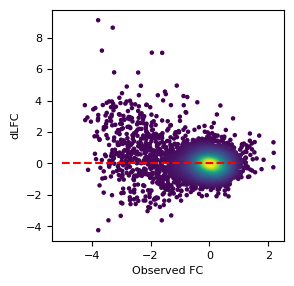

In [18]:
x, y, z = hw.get_density_for_scatter( paralog_sl_meljuso.fcOBS, paralog_sl_meljuso.dLFC )

figure( figsize=(3,3))
scatter( x, y, c=z, s=5)
plot([-5,1],[0,0], 'r--')
#xlim(-15,2.5)
#ylim(-15,2.5)
xlabel('Observed FC')
#xlabel('Expected')
ylabel('dLFC')
#savefig("./")
savefig("./Fig4_A_dLFC_Obs_Meljuso.pdf",bbox_inches='tight')
show()


# Meljuso _ Paralog_example

In [19]:
Paralog_pair = gene_fc[(gene_fc.index.str.count("_")==1) & (~gene_fc.index.str.contains(","))].reset_index()
Paralog_pair[["GENE1", "GENE2"]] = Paralog_pair.GENE.str.split("_", expand=True, n=1)
Paralog_pair

,GENE,Meljuso,Meljuso_sel,A375,GENE1,GENE2
0,AAK1_BMP2K,-0.50175,-1.06475,-1.22750,AAK1,BMP2K
1,AARS1_AARS2,-3.34325,-3.39200,-3.84950,AARS1,AARS2
2,ABCA2_ABCA3,-0.16125,0.01350,0.22900,ABCA2,ABCA3
3,ABCA2_ABCA7,0.09550,-0.07725,-0.21425,ABCA2,ABCA7
4,ABCA3_ABCA7,-0.09250,-0.16325,-0.51225,ABCA3,ABCA7
...,...,...,...,...,...,...
4416,ZSCAN30_ZSCAN31,0.70250,0.88200,0.29850,ZSCAN30,ZSCAN31
4417,ZSCAN30_ZSCAN9,0.43300,0.24000,0.35400,ZSCAN30,ZSCAN9
4418,ZSCAN31_ZSCAN9,0.12625,0.27275,0.41475,ZSCAN31,ZSCAN9
4419,ZSWIM4_ZSWIM6,-0.46800,-0.36675,-0.14700,ZSWIM4,ZSWIM6


In [20]:
gene_fc_s_p = gene_fc[(gene_fc.index.isin(Paralog_pair.GENE)) | (gene_fc.index.isin(Paralog_pair.GENE1)) | (gene_fc.index.isin(Paralog_pair.GENE2))]
gene_fc_s_p = gene_fc_s_p[["Meljuso"]]
gene_fc_s_p

,Meljuso
GENE,
AAK1,-0.67875
AAK1_BMP2K,-0.50175
AARS1,-3.98375
AARS1_AARS2,-3.34325
AARS2,-2.05400
...,...
ZSWIM6,-0.63175
ZXDB,1.03675
ZXDB_ZXDC,0.33100


In [21]:
df = pd.DataFrame(index = Paralog_pair.GENE, columns= ["Gene1", "Gene2", "Paralog"])
df.head()

,Gene1,Gene2,Paralog
GENE,,,
AAK1_BMP2K,NaN,NaN,NaN
AARS1_AARS2,NaN,NaN,NaN
ABCA2_ABCA3,NaN,NaN,NaN
ABCA2_ABCA7,NaN,NaN,NaN
ABCA3_ABCA7,NaN,NaN,NaN


In [22]:
for i in df.index:
    g1, g2 = i.split("_")
    try:
        df.loc[i]["Gene1"] = gene_fc_s_p.loc[g1]["Meljuso"]
        df.loc[i]["Gene2"] = gene_fc_s_p.loc[g2]["Meljuso"]
        df.loc[i]["Paralog"] = gene_fc_s_p.loc[i]["Meljuso"]
    except:
        pass

In [23]:
df_significant = df[(df["Paralog"]< -2.5) & (df["Gene1"]> -1) & (df["Gene2"]> -1)]
#df_significant = df_significant.reset_index()
df_significant.head(3)

,Gene1,Gene2,Paralog
GENE,,,
ATP1B1_ATP1B3,-0.53875,-0.78625,-2.93275
CAPZA1_CAPZA2,-0.0885,-0.45925,-2.7055
CEPT1_CHPT1,-0.45025,0.35775,-2.68125


In [34]:
def make_plot(paralogs):
    data = fc[["GENE", "Meljuso"]]
    g1,g2 = paralogs.split("_")
    data = data[(data["GENE"] ==paralogs)| (data["GENE"] ==g1)| (data["GENE"] ==g2)]
    figsize(1.5,3)
    sns.barplot(x ="GENE", y ="Meljuso", data = data, errorbar=None, color = "lightblue")
    sns.swarmplot(x = "GENE", y = "Meljuso", data = data, color = "black")
    xticks(rotation = 90), xlabel("")
    ylabel("Observed LFC"), ylim (-4.5,1)
    title_name = f"{paralogs}"
    savefig(title_name + '.pdf', bbox_inches="tight")

In [35]:
df_significant.index

Index(['ATP1B1_ATP1B3', 'CAPZA1_CAPZA2', 'CEPT1_CHPT1', 'CNOT7_CNOT8',
       'CUL4A_CUL4B', 'DDX19A_DDX19B', 'HSP90AA1_HSP90AB1', 'KDELR1_KDELR2',
       'MAGOH_MAGOHB', 'NXT1_NXT2', 'PPP1CA_PPP1CC', 'SAR1A_SAR1B',
       'SRPK1_SRPK2', 'STXBP1_STXBP3', 'TIA1_TIAL1', 'UBE2A_UBE2B',
       'YWHAE_YWHAZ'],
      dtype='object', name='GENE')

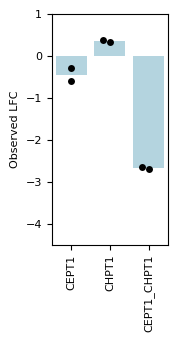

In [37]:
make_plot("CEPT1_CHPT1")

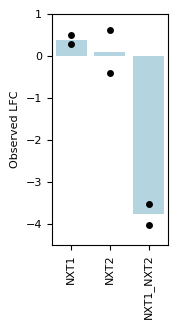

In [38]:
make_plot("NXT1_NXT2")

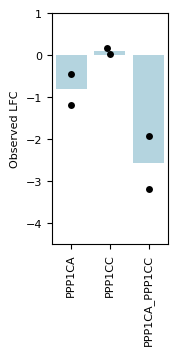

In [39]:
make_plot("PPP1CA_PPP1CC")

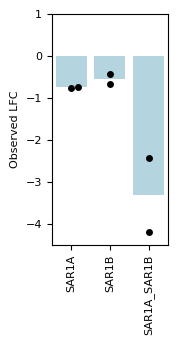

In [40]:
make_plot("SAR1A_SAR1B")

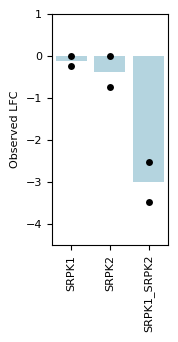

In [41]:
make_plot("SRPK1_SRPK2")